In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models 
import matplotlib.pyplot as plt

I0000 00:00:1793362514.872674    1511 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793362515.331985    1511 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793362518.126798    1511 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
dataset=tf.keras.preprocessing.image_dataset_from_directory(
   "potato-disease",
    image_size=(256,256),
    batch_size=32,
    shuffle=True,
)

Found 2152 files belonging to 3 classes.


I0000 00:00:1793362523.504951    1511 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [3]:
class_names=dataset.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [4]:
len(dataset)

68

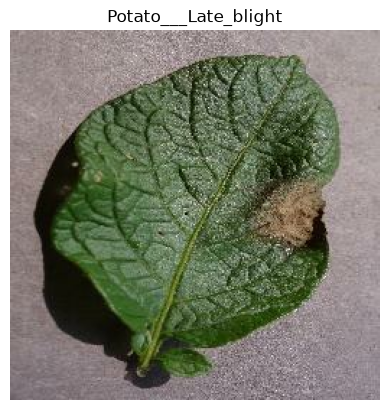

In [5]:
for image,label in dataset.take(1):
    # print(image)
    # print(label)
    plt.imshow(image[0].numpy().astype('uint8'))
    plt.title(class_names[label[0]])
    plt.axis('off')
    plt.show()

In [6]:
train_size=len(dataset)*0.8
train_dataset=dataset.take(int(train_size))
len(train_dataset)


54

In [7]:
test_ds=dataset.skip(int(train_size))
len(test_ds)

14

In [8]:
val_size=0.1
len(dataset)*val_size

6.800000000000001

In [9]:
val_ds=test_ds.take(6)

In [16]:
def get_dataset_partitions(
    ds,
    train_split=0.8,
    val_split=0.1,
    test_split=0.1,
    shuffle=True,
    shuffle_size=10000
):
    if shuffle:
        ds = ds.shuffle(buffer_size=shuffle_size, seed=12)

    dataset_size = len(ds)

    train_size = int(train_split * dataset_size)
    val_size = int(val_split * dataset_size)

    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size + val_size)

    return train_ds, val_ds, test_ds

In [17]:
train_ds,val_ds,test_ds=get_dataset_partitions(dataset)

In [18]:
len(train_ds),len(val_ds),len(test_ds)

(54, 6, 8)

In [19]:
train_ds=train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds=val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds=test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

In [20]:
rescaling_layer=tf.keras.Sequential([
    layers.Resizing(256,256),
    layers.Rescaling(1./255)])

In [21]:
data_augmentation=tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2)
])

In [28]:
model=models.Sequential([
    rescaling_layer,
    data_augmentation,
    layers.Conv2D(16,3,input_shape=(256,256,3),activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32,3,input_shape=(256,256,3),activation='relu'),
    layers.MaxPooling2D(),  
    layers.Conv2D(64,3,input_shape=(256,256,3),activation='relu'),  
    layers.MaxPooling2D(),
    layers.conv2D(128,3,input_shape=(256,256,3),activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dense(len(class_names),activation='softmax')
    ])
model.build(input_shape=(None,256,256,3))

/home/manoj/tensorflow-gpu/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


AttributeError: module 'keras._tf_keras.keras.layers' has no attribute 'conv2D'

In [24]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 254, 254, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 127, 127, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 125, 125, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 60, 60, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,396,899 (28.22 MB)

 Trainable params: 7,396,899 (28.22 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])


In [27]:
history=model.fit(train_ds,
          validation_data=val_ds,
          epochs=50,
          batch_size=32)

Epoch 1/50


/home/manoj/tensorflow-gpu/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793364596.764396    2044 cuda_dnn.cc:461] Loaded cuDNN version 92501


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.7297 - loss: 0.6426

I0000 00:00:1793364635.275451    8528 shuffle_dataset_op.cc:453] ShuffleDatasetV3:11: Filling up shuffle buffer (this may take a while): 26 of 10000
I0000 00:00:1793364637.341839    8528 shuffle_dataset_op.cc:483] Shuffle buffer filled.
I0000 00:00:1793364637.372285    8528 shuffle_dataset_op.cc:483] Shuffle buffer filled.
W0000 00:00:1793364637.373141    8526 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 25166080 bytes after encountering the first element of size 25166080 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


54/54 ━━━━━━━━━━━━━━━━━━━━ 55s 750ms/step - accuracy: 0.7297 - loss: 0.6426 - val_accuracy: 0.8490 - val_loss: 0.5123
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 13s 231ms/step - accuracy: 0.8756 - loss: 0.3280 - val_accuracy: 0.8906 - val_loss: 0.3566
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 183ms/step - accuracy: 0.8895 - loss: 0.2730 - val_accuracy: 0.8906 - val_loss: 0.2675
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 12s 228ms/step - accuracy: 0.9201 - loss: 0.2227 - val_accuracy: 0.8542 - val_loss: 0.4233
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - accuracy: 0.9230 - loss: 0.1971 - val_accuracy: 0.9271 - val_loss: 0.2100
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - accuracy: 0.9392 - loss: 0.1612 - val_accuracy: 0.9062 - val_loss: 0.2082
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 98ms/step - accuracy: 0.9578 - loss: 0.1210 - val_accuracy: 0.9323 - val_loss: 0.1549
Epoch 8/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.9340 - loss: 0.1918 - val_accuracy: 0.8594 - val

In [29]:
model.evaluate(test_ds)

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.9766 - loss: 0.0598


[0.05983678624033928, 0.9765625]

In [30]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

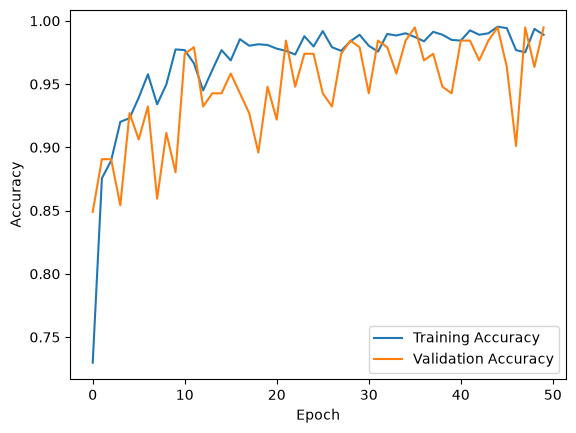

In [34]:




acc=history.history['accuracy']
val_acc=history.history['val_accuracy']
loss=history.history['loss']
val_loss=history.history['val_loss']
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

first image
first label: Potato___Late_blight
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step
prediction: Potato___Late_blight


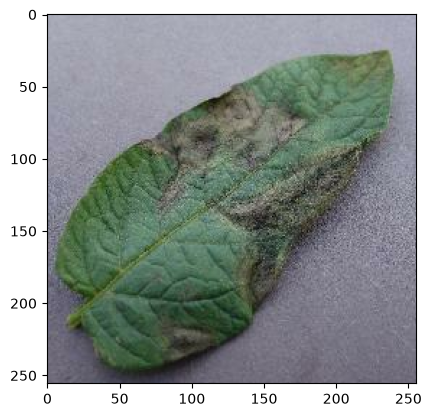

In [61]:
#each batch contains 32 images and labels
import numpy as np

for image,batch in test_ds.take(1):
    first_image = image[31].numpy().astype('uint8')
    first_label = batch[31].numpy()
    plt.imshow(first_image)
    print("first image")
    print("first label:", class_names[first_label])
    prediction = model.predict(image)
    print("prediction:", class_names[np.argmax(prediction[31])])


In [62]:
def predict(model,img):
    img_array=tf.keras.preprocessing.image.img_to_array(img)
    img_array=tf.expand_dims(img_array,0)
    prediction=model.predict(img_array)
    confidence=round(100*(np.argmax(prediction[0])),2)
    return prediction, confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


W0000 00:00:1793367428.526896    1511 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 25166080 bytes after encountering the first element of size 25166080 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


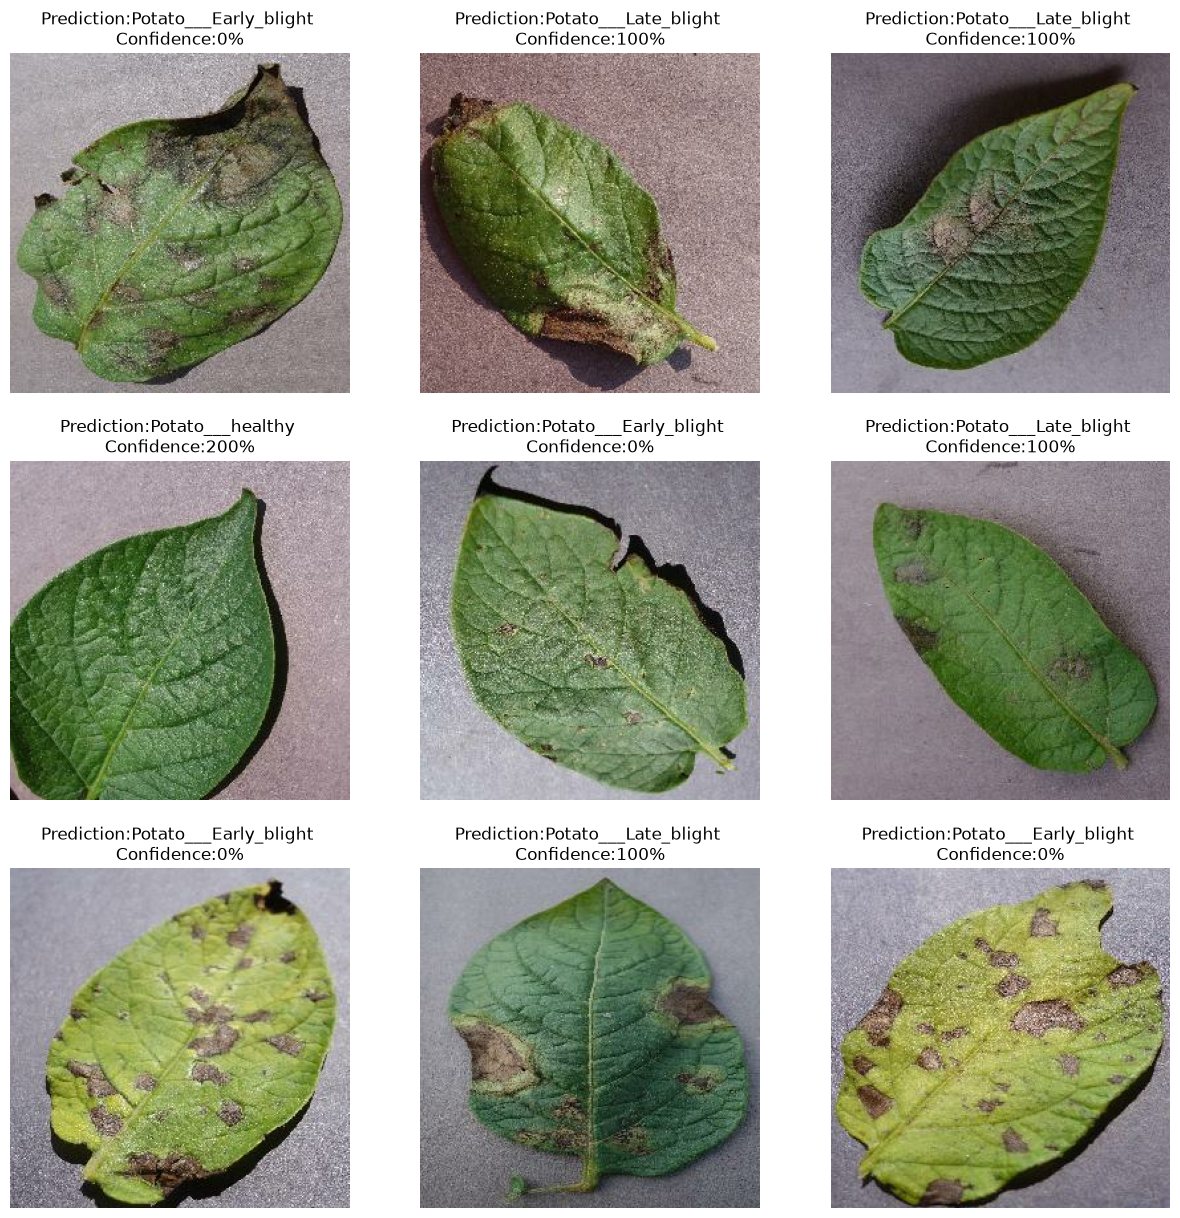

In [68]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,15))
for image,label in test_ds.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(image[i].numpy().astype('uint8'))
        prediction,confidence=predict(model,image[i])
        actual_label=class_names[label[i]]
        plt.title(f"Prediction:{class_names[np.argmax(prediction[0])]} \nConfidence:{confidence}%")
        plt.axis('off')